## Module 3: Computational Drug Discovery Project Project Notebook

By: Joseph Blumberg and Travis Heinrichs

## Project Goal:

We are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Our overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Our project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.

## Disease Background:

Obesity, defined in adults as a body mass index (BMI) of 30 kg/m² or more, affected about 1 in 7 people worldwide in 2024 and raises the risk of type 2 diabetes, heart disease, and several cancers. Standard care includes diet, exercise, medicines, and bariatric surgery (WHO, 2026).

After meals, the gut releases GLP-1, which activates the GLP-1 receptor, a G-protein coupled receptor, to boost insulin, slow stomach emptying, and reduce appetite (Seino et al., 2010). In separate trials, weekly 2.4 mg semaglutide injections reduced body weight by 14.9% vs. 2.4% with placebo at 68 weeks (Wilding et al., 2021), and a daily 25 mg pill reduced it by 13.6% vs. 2.2% at 64 weeks, though 74% of pill users had gastrointestinal side effects (Wharton et al., 2025).

Only about 1% of oral semaglutide is absorbed, making oral bioavailability an important challenge for treatments like Cavalitide (Overgaard et al., 2021).

To best treat obesity, our team is modeling the activations of this GLP-1 receptor at varying administrations of GLP-1 agonist drugs. How do they compare in terms of the doses required to achieve different levels of GLP-1 activation? How do their blood concentrations vary with dose and absorption rate?

## Task 1: Fit a receptor binding model for Cavalitide:

Our colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (available as cavalitide_data.csv). We now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt our previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

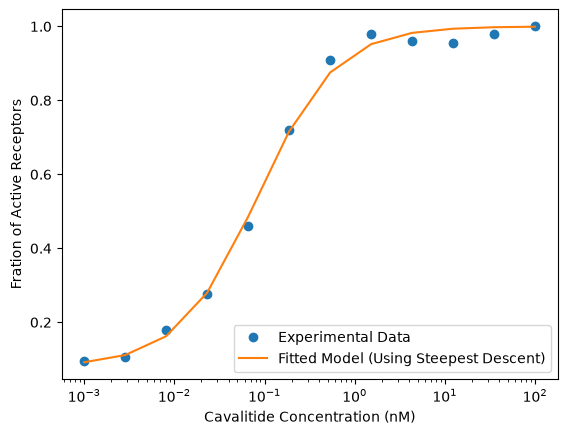

Fitted Kd for Cavalitide: 0.07696604134715376 nM
Refined the Kd found with steepest descent using Brute force Kd: 0.07697487437185929 nM
Curve fit SSE: 0.005154346389845313
Brute force SSE: 0.005154348204638565


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

data = pd.read_csv("cavalitide_data.csv") #load experimental receptor activation data

cavalitide_conc = data["L2_nM"].to_numpy() #assign variables to columns of experimental data, cavalatide concentrations in nM
exp_F_act = data["Fact"].to_numpy()#assign variables to columns of experimental data, experimentally measured receptor activation

def find_F_act(cavalitide_conc, Kd_C): #gives the fraction of active receptors using inputted Cavalitide concetration and its Kd, Kd_G (0.17 [nM]) and GLP1 concentration (0.015 nM) are set as constant
    return ((0.015/0.17) + (cavalitide_conc/Kd_C))/ (1 + (0.015/0.17) + (cavalitide_conc/Kd_C))

popt, pcov = curve_fit(find_F_act, cavalitide_conc, exp_F_act, p0 = [0.1]) #initial guess is Kd_C = 0.1

Kd_C = popt[0]

plt.figure()
plt.semilogx(cavalitide_conc, exp_F_act, "o", label = "Experimental Data")
plt.xlabel("Cavalitide Concentration (nM)")
plt.ylabel("Fration of Active Receptors")
plt.semilogx(cavalitide_conc, find_F_act(cavalitide_conc, Kd_C), label = "Fitted Model (Using Steepest Descent)")
plt.legend()
plt.title("Cavalatide Receptor Binding Model")
plt.show()

print("Fitted Kd for Cavalitide:", Kd_C, "nM") #returns 0.077 nM

#Let's refine it further with brute force!
def SSE(Kd_C):
    return np.sum((exp_F_act - find_F_act(cavalitide_conc, Kd_C))**2) #finds the sum of squared errors between my experimental and predicted values
# Brute force optimization by looping over Kd_C
Kd_range = np.linspace(0.072, 0.082, 200) #generates 200 evenly spaced possible values between 0.072 and 0.082 nM
SSE_values = np.zeros(len(Kd_range)) #creates an empty array containing 200 zeroes

for i in range(len(Kd_range)): #records the SSE at every Kd in my set of values called Kd_range
    SSE_values[i] = SSE(Kd_range[i])

best_Kd = Kd_range[np.argmin(SSE_values)] #find index of smallest SSE then retrieve the corresponding Kd
print("Refined the Kd found with steepest descent using Brute force Kd:", best_Kd, "nM")

#compare the methods:
print("Curve fit SSE:", SSE(Kd_C))
print("Brute force SSE:", SSE(best_Kd)) #curve fit still wins!

**Observations:** As the Kd of Semaglutide is 0.350 nM and the Kd of Cavalitide is 0.077 nM, Cavalitide has over 4.5 times the binding affinity to the GLP-1 receptor! In other words, the curve for the fraction of activated receptors for Semaglutide is farther right than that of Cavalitide. The advantage of Cavalitide is that it takes less dose to achieve the same receptor activation. Maybe this brings the cost down! The disadvantage is that the higher binding affinity may mean Cavalitide has greater side effects or the body might not be able to eliminate it for an undesired time.


## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Our boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill). Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

Task 2, part 1:
Here is the code that graphs the levels of Ozempic at the injection site and in the blood throughout the course of the proper administration.

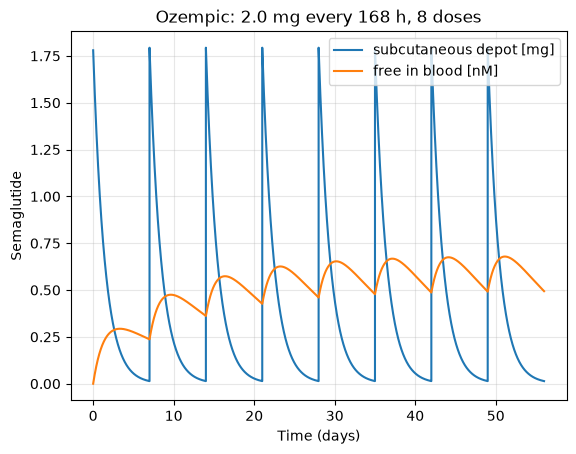

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

drug = 'Ozempic'


# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # Euler steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        y_seg = np.zeros((2, n_steps + 1))
        y_seg[:, 0] = y
        
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval = t_seg)
        y_seg = sol.y
            
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Semaglutide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Here is the code that graphs the levels of Wegovy at the injection site and in the blood throughout the course of the proper administration.

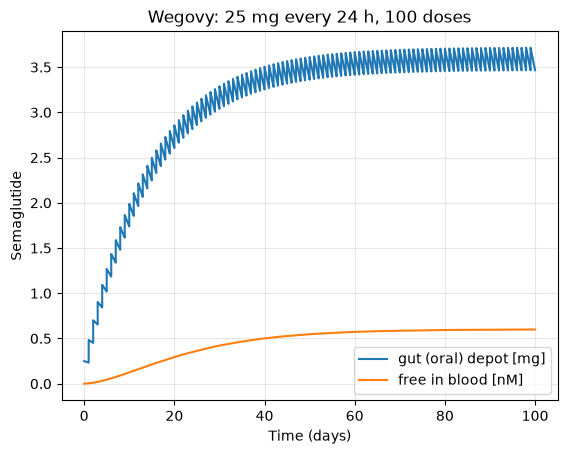

In [11]:
drug = 'Wegovy'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # Euler steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        y_seg = np.zeros((2, n_steps + 1))
        y_seg[:, 0] = y
        
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval = t_seg)
        y_seg = sol.y
            
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Semaglutide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Observations:** It looks like the concentration of Wegovy in the blood is more steady over the time of its administration than the concentration of Ozempic. This is due to more frequent dosing and a smaller absorption rate constant, which means the drug is absorbed slower and more gradually into the bloodstream. A smaller Ka also means that more drug remains in the absorption site for longer. As shown in the graphs, the amount of drug in the gut depot with Wegovy approaches a steady range around 3.5 mg, while the amount of Ozempic at the subcutaneous injection site decreases nearly to 0 between doses.

Task 2, part 2:  Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.

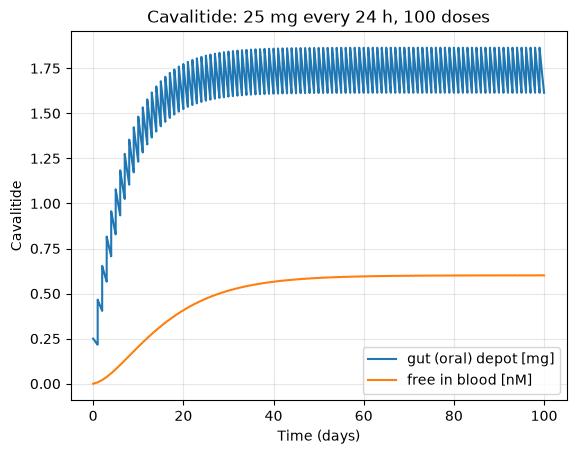

In [17]:
#task 2
drug = 'Cavalitide'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    'Cavalitide': dict(
        Favailable = 0.01,
        ka = 0.006,
        D = 25,
        interval = 24,
        n_doses = 100,
        depot='gut (oral)')
}

p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # Euler steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        y_seg = np.zeros((2, n_steps + 1))
        y_seg[:, 0] = y
        
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval = t_seg)
        y_seg = sol.y
            
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Cavalitide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Observations:** The amount in the gut depot is lower with Cavalitide than Wegovy because of the higher absorption rate from the gut to the blood. For the same reason, the amount in the gut depot would fluctuate more between doses with Cavalitide. Both Wegovy and Cavalitide achieved steady concentrations in the blood because they are both taken daily.

Task 2, part 3: Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

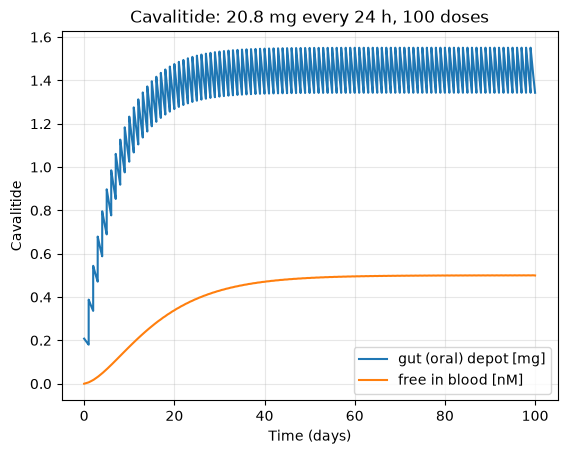

In [22]:
drug = 'Cavalitide'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    'Cavalitide': dict(
        Favailable = 0.01,
        ka = 0.006,
        D = 20.8,
        interval = 24,
        n_doses = 100,
        depot='gut (oral)')
}

p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # Euler steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        y_seg = np.zeros((2, n_steps + 1))
        y_seg[:, 0] = y
        
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval = t_seg)
        y_seg = sol.y
            
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Cavalitide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


To lower the steady-state concentration of Cavalitide in the blood, we lowered the dose taken each day such that less drug would enter the bloodstream over time. Before, 25 mg was taken daily, and that achieved a steady-state concentration of about 0.6 nM. To determine the new dose needed to achieve 0.5 nM in the blood, we multiplied 25 times (0.5/0.6) to get 20.8 mg. This works because the rate at which the drug enters the bloodstream is directly proportional to the amount remaining in the gut depot, as modeled by the equations dAsc = -ka*Asc and dCc = ka*Asc/V - ke*Cc.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


Task 3, part 1: Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let's call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment.

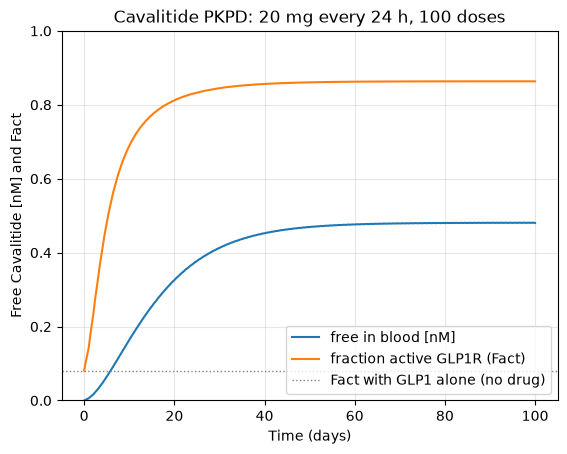

Fact with GLP1 alone (day 0) = 0.081
First day with Fact above 0.5 = day 5.3
Free Cavalitide at day 100 = 0.480 nM
Fact at day 100 = 0.863


In [23]:
#task 3, part 1: cavalitidePKPD.py = PK model from Task 2 + receptor binding (PD) model from Task 1
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

drug = 'Cavalitide'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    'Cavalitide': dict(
        Favailable = 0.01,
        ka = 0.006,
        D = 20,            # mg, Phase 1 dose from Task 2 (gives ~0.5 nM free in blood)
        interval = 24,     # daily pill
        n_doses = 100,     # 100 daily doses = first 100 days of treatment
        depot='gut (oral)')
}

p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of drug bound to albumin

# simulation parameters
dt = 0.1        # h, time step between output points

# receptor binding (PD) parameters
Kd1 = 0.17      # [nM] GLP1
Kd2 = 0.077     # [nM] Cavalitide, our fitted Kd from Task 1
L1 = 0.015      # [nM] GLP1 (fasting), same value used in Task 1

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # time steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval = t_seg)  # solve the ODEs until the next dose
        y_seg = sol.y
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 (GLP1) and L2 (Cavalitide),
    same model as find_F_act in Task 1"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# --- run PK model ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- PD model: only free Cavalitide (not bound to albumin) can bind the GLP1 receptor ---
L2 = Ffree*Cc                       # [nM] free Cavalitide in blood over time
Fact_t = Fact(L1, L2, Kd1, Kd2)     # fraction of active GLP1R over time

# --- plot ---
plt.figure()
plt.plot(t / 24, L2, label="free in blood [nM]")
plt.plot(t / 24, Fact_t, label="fraction active GLP1R (Fact)")
plt.axhline(Fact(L1, 0, Kd1, Kd2), ls=":", c="gray", lw=1, label="Fact with GLP1 alone (no drug)")
plt.ylim(0, 1)
plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide [nM] and Fact")
plt.title(f"{drug} PKPD: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Fact with GLP1 alone (day 0) = {Fact(L1, 0, Kd1, Kd2):.3f}")
print(f"First day with Fact above 0.5 = day {t[Fact_t > 0.5][0]/24:.1f}")   # first time point with over half the receptors active
print(f"Free Cavalitide at day 100 = {L2[-1]:.3f} nM")
print(f"Fact at day 100 = {Fact_t[-1]:.3f}")

**Part 1 results:** We combined the two models by feeding the free Cavalitide concentration from our PK model (Task 2) into the two-ligand receptor model, Fact(L1, L2, Kd1, Kd2), from GLP1_GLP1R.py (BME 2315 Module 3 example code). We used our fitted Kd of 0.077 nM (Task 1) and fasting GLP1 (0.015 nM). Only free drug (the 1% not bound to albumin) can bind the receptor.

At the Phase 1 dose (20 mg pill once a day):
- Before treatment, GLP1 alone keeps only 8% of receptors active.
- Fact passes 50% at about day 5 and levels off at about 86% (Fact = 0.863 at day 100).
- Fact rises much faster than the drug level. Free Cavalitide takes about 40-50 days to level off at 0.48 nM, but Fact is already above 0.8 by day 20. Cavalitide binds so tightly (Kd = 0.077 nM) that even a small amount of drug activates most receptors.
- With daily dosing, both curves are smooth at steady state, with no visible peaks or troughs.

Task 3, part 2: Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days). Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.

Brute-force dose = 29 mg every 24 h (squared error = 0.000002)
20 mg: free Cavalitide at day 100 = 0.480 nM, Fact at day 100 = 0.863
29 mg: free Cavalitide at day 100 = 0.696 nM, Fact at day 100 = 0.901


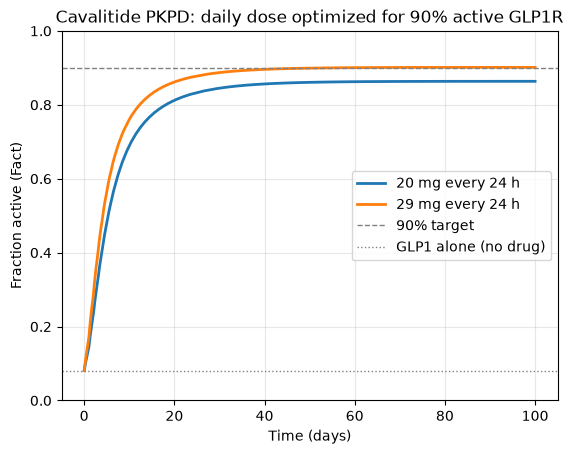

In [24]:
#task 3, part 2: find the daily dose that gives ~90% active GLP1R at steady state (day 100)
Fact_target = 0.90      # goal: 90% of GLP1 receptors active

# Brute force optimization of the dose D: try many candidate doses in a for loop
# (same method as Approach 1 in fit_semaglutide_GLP1R.py)
D_candidates = np.arange(20, 41, 1)   # [mg] candidate daily doses, 20 to 40 mg
SE_brute = np.inf
for D_try in D_candidates:
    t, Asc, Cc = simulate(D_try, n_doses, interval, dt)
    Fact_ss = Fact(L1, Ffree*Cc[-1], Kd1, Kd2)    # Fact at day 100 (steady state)
    SE = (Fact_ss - Fact_target)**2               # squared error from the 90% goal
    if SE < SE_brute:
        SE_brute = SE
        D_brute = D_try
print(f"Brute-force dose = {D_brute} mg every {interval} h (squared error = {SE_brute:.6f})")

# --- compare the Phase 1 dose (20 mg) with the optimized dose ---
plt.figure()
for D_plot in [20, D_brute]:
    t, Asc, Cc = simulate(D_plot, n_doses, interval, dt)
    Fact_t = Fact(L1, Ffree*Cc, Kd1, Kd2)
    plt.plot(t / 24, Fact_t, lw=2, label=f"{D_plot} mg every {interval} h")
    print(f"{D_plot} mg: free Cavalitide at day 100 = {Ffree*Cc[-1]:.3f} nM, Fact at day 100 = {Fact_t[-1]:.3f}")
plt.axhline(Fact_target, ls="--", c="gray", lw=1, label="90% target")
plt.axhline(Fact(L1, 0, Kd1, Kd2), ls=":", c="gray", lw=1, label="GLP1 alone (no drug)")
plt.ylim(0, 1)
plt.xlabel("Time (days)")
plt.ylabel("Fraction active (Fact)")
plt.title(f"{drug} PKPD: daily dose optimized for 90% active GLP1R")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Which dosing parameter did we adjust?** We changed only the dose D, from 20 mg to 29 mg, and kept the once-daily pill (interval = 24 h). We used a brute-force search over daily doses from 20 to 40 mg, the same method used in fit_semaglutide_GLP1R.py (BME 2315 Module 3, Lecture 3). 29 mg came closest to the goal: 0.696 nM free Cavalitide and Fact = 0.901 at day 100. We kept daily dosing because a once-a-day pill is easy for patients and matches the Wegovy pill. In our model the steady-state drug level is proportional to the dose, so changing the dose alone was the simplest way to hit the target.

**Clinical benefits of this adjustment:**
- **Stronger effect:** 90% instead of 86% active GLP1 receptors should mean more insulin release, slower stomach emptying, and less appetite ([Seino et al., 2010](https://doi.org/10.1111/j.2040-1124.2010.00022.x)), which should lead to more weight loss and better blood sugar control.
- **Faster onset:** The 29 mg curve rises faster, so patients reach high receptor activation sooner.
- **Steady effect:** With a daily pill, receptor activation stays almost flat at steady state, unlike a weekly shot that rises and falls each week (see the comparison below).

**Trade-off:** We needed 45% more drug (20 to 29 mg) for only 4 more percentage points of active receptors, because the receptors are already close to saturated. A higher dose could also raise cost and stomach side effects, which are already common with GLP-1 drugs ([Wharton et al., 2025](https://doi.org/10.1056/NEJMoa2500969)). The Phase 2 trial should test whether this extra receptor activation gives meaningfully more weight loss.

Task 3, comparison with semaglutide: To support our Conclusions, we ran the same PKPD model for Ozempic (2 mg injection once a week) and the Wegovy pill (25 mg once a day), using semaglutide's Kd (0.35 nM, from Task 1). The only differences between the three drugs are bioavailability, absorption rate (ka), dose, dosing interval, and Kd.

Ozempic: average Fact in days 93-100 = 0.646
Wegovy: average Fact in days 93-100 = 0.643
Cavalitide: average Fact in days 93-100 = 0.901


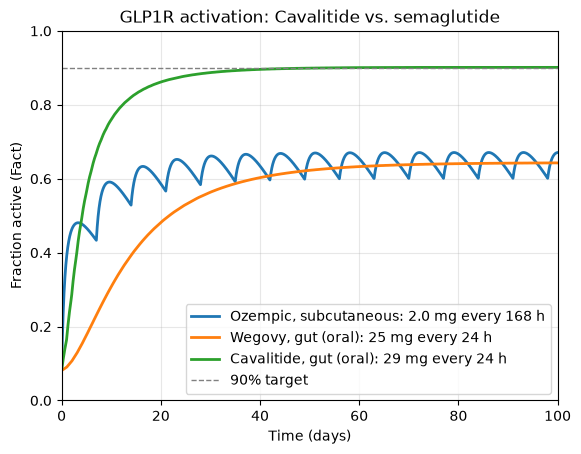

In [25]:
#task 3, comparison: GLP1R activation for Cavalitide vs. semaglutide (Ozempic and Wegovy) over 100 days
Kd_drugs = {'Ozempic': 0.35,      # [nM] semaglutide Kd (value used in Task 1)
            'Wegovy': 0.35,       # [nM] semaglutide Kd
            'Cavalitide': 0.077}  # [nM] Cavalitide Kd fitted in Task 1
products['Ozempic']['n_doses'] = 15       # 15 weekly shots so Ozempic also covers 100 days
products['Cavalitide']['D'] = D_brute     # optimized Cavalitide dose from part 2

plt.figure()
for drug in ['Ozempic', 'Wegovy', 'Cavalitide']:
    p = products[drug]
    Favailable, ka, D = p['Favailable'], p['ka'], p['D']
    interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']
    t, Asc, Cc = simulate(D, n_doses, interval, dt)
    Fact_t = Fact(L1, Ffree*Cc, Kd1, Kd_drugs[drug])     # same receptor model, each drug's own Kd
    plt.plot(t / 24, Fact_t, lw=2, label=f"{drug}, {depot}: {D} mg every {interval} h")
    last_week = (t >= 93*24) & (t <= 100*24)              # time points in days 93 to 100
    print(f"{drug}: average Fact in days 93-100 = {np.mean(Fact_t[last_week]):.3f}")
plt.axhline(0.90, ls="--", c="gray", lw=1, label="90% target")
plt.xlim(0, 100)
plt.ylim(0, 1)
plt.xlabel("Time (days)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation: Cavalitide vs. semaglutide")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

**Comparison results:** Over days 93-100, Cavalitide at 29 mg/day keeps about 90% of GLP1 receptors active, compared with about 64% for the Wegovy pill and about 65% on average for Ozempic, whose activation also rises and falls every week. Cavalitide also levels off within about 40 days, while the Wegovy pill is still slowly rising after day 60, because Cavalitide is absorbed about twice as fast (ka = 0.006 vs. 0.0029 1/h).

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

Our analyses suggest that Cavalitide could compete well with semaglutide, especially with the oral form (the Wegovy pill):

- **Tighter binding (Task 1):** Cavalitide's fitted Kd (0.077 nM) is about 4.5 times lower than semaglutide's (0.35 nM in Task 1). Less free drug is needed to activate the same fraction of GLP1 receptors.
- **Faster absorption (Task 2):** Cavalitide is absorbed about twice as fast as the Wegovy pill (ka = 0.006 vs. 0.0029 1/h). A 20.8 mg daily pill reached our 0.5 nM target of free drug in the bloodstream (after albumin binding), and Cavalitide reaches steady state sooner.
- **More active receptors (Task 3):** At 29 mg/day, Cavalitide keeps about 90% of GLP1 receptors active. In the same model, the Wegovy pill (25 mg/day) reaches about 64% and Ozempic (2 mg/week injection) averages about 65%.
- **A pill instead of a shot:** Cavalitide could give higher and steadier receptor activation than injected semaglutide without needles.

There are also reasons for caution. Our model assumes only 1% of each Cavalitide pill is absorbed, like oral semaglutide (Overgaard et al., 2021), so most of the drug is wasted. The pill also has to be taken every day, while Ozempic is one shot a week. Finally, our model predicts receptor activation, not weight loss or side effects.

Overall, Cavalitide looks promising enough to move into a Phase 2 trial at about 29 mg once a day. The key question for that trial is whether ~90% receptor activation gives more weight loss than semaglutide without more side effects.

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

Our PK model is simple. It uses one blood compartment with first-order absorption and elimination, leaves out a peripheral compartment, and treats every patient the same. Only ka and Kd are specific to Cavalitide; its bioavailability, volume, elimination rate, molecular weight, and albumin binding all come from semaglutide, even though Cavalitide is a small molecule and these values are likely different. The receptor model assumes equilibrium binding, keeps GLP1 at its fasting level even though it rises after meals, and ignores receptor desensitization over months of treatment. Our Kd also came from one 12-point dataset with no uncertainty estimate. Finally, the model stops at receptor activation, so it cannot predict weight loss or side effects, and it assumes every daily pill is taken on time. With more time and data, we would fit Cavalitide's own PK parameters to Phase 1 blood data using curve_fit, add a peripheral compartment and patient-to-patient variation, report the uncertainty in Kd, and link receptor activation to weight loss and side effects to choose the dose with the best balance.

## AI Usage Statement:

AI was used in assisting in fixing bugs, providing guidance with code, and also with finding sources for discussion, future works, and limitations section. We also used it to reword some sentences for better clarity.

## GitHub Repository Link:
https://github.com/TravisHeinrichs/BME2315_Module3


## References:

1. World Health Organization. (2026). Obesity and overweight [Fact sheet]. [WHO fact sheet](https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight). Accessed November 16, 2026.
2. Seino, Y., Fukushima, M., & Yabe, D. (2010). GIP and GLP-1, the two incretin hormones: Similarities and differences. *Journal of Diabetes Investigation, 1*(1-2), 8-23. [DOI](https://doi.org/10.1111/j.2040-1124.2010.00022.x).
3. Wilding, J. P. H., et al. (2021). Once-weekly semaglutide in adults with overweight or obesity (STEP 1). *New England Journal of Medicine, 384*, 989-1002. [DOI](https://doi.org/10.1056/NEJMoa2032183).
4. Wharton, S., et al. (2025). Oral semaglutide at a dose of 25 mg in adults with overweight or obesity (OASIS 4). *New England Journal of Medicine, 393*(11), 1077-1087. [DOI](https://doi.org/10.1056/NEJMoa2500969).
5. Overgaard, R. V., et al. (2021). Clinical pharmacokinetics of oral semaglutide: Analyses of data from clinical pharmacology trials. *Clinical Pharmacokinetics, 60*(10), 1335-1348. [DOI](https://doi.org/10.1007/s40262-021-01025-x).
6. BME 2315 course example code (provided). `ligand_receptor.py`, `GLP1_GLP1R.py`, `fit_semaglutide_GLP1R.py`, and `semaglutidePK.py`. Adapted for the Task 3 PKPD model.
7. Saucerman, J. (2026). BME 2315 Module 3, Lectures 1-3 and November 10 class notes. Computational drug discovery.

## NOTES FROM YOUR TEAM: 
We both attended every class for this module, but we decided to rely on the posted material as our notes. They can be found under Module 3 in Canvas.

## QUESTIONS FOR YOUR TA: 
No questions.